In [1]:
import re
import sys
import config as C
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from src import save_plot, blosum_of
from scipy.cluster.hierarchy import fcluster, leaves_list, linkage
from scipy.spatial.distance import squareform

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
EDIT_KEY = ["chromosome", "position", "genomic_ref", "genomic_alt"]
CATEGORY_COLOUR = {"Missense": "#009ADE", "Silent": "#9aa0a6", "Nonsense": "#FF1F5B"}

sys.path.insert(0, str(ROOT))

# Variant annotations


In [2]:
annotation = pd.read_csv(C.dataset_file(C.THIS_STUDY, "annotation"), low_memory=False)

# the ProtVar structural features live in their own table, keyed by the edit
structure = pd.read_csv(C.DATA / "features_variant_structure.csv")
structure = structure.astype({"chromosome": annotation.chromosome.dtype})
PROTVAR = [
    "foldx_ddg", "plddt", "pocket_buriedness", "pocket_score", "in_predicted_pocket",
    "interface_count", "interface_max_pdockq", "is_in_interface",
]
annotation = annotation.merge(
    structure[EDIT_KEY + PROTVAR].drop_duplicates(EDIT_KEY), on=EDIT_KEY, how="left"
)

annotation["blosum62"] = blosum_of(annotation.vep_aaref, annotation.vep_aaalt)

counts = annotation.drop_duplicates(["guide", *EDIT_KEY]).guide.value_counts()
single = set(counts[counts == 1].index)
variants = annotation[annotation.guide.isin(single)].drop_duplicates("guide").copy()
print(f"{len(variants):,} sgRNAs installing exactly one edit, "
      f"{variants[PROTVAR].notna().any(axis=1).sum():,} with a structural record")

14,043 sgRNAs installing exactly one edit, 7,675 with a structural record


/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_66074/1144737183.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  annotation["blosum62"] = blosum_of(annotation.vep_aaref, annotation.vep_aaalt)


In [3]:
variants

,guide,study,editor,gene,chromosome,position,genomic_ref,genomic_alt,guide_position,guide_edit,...,spliceai_dp_dl,foldx_ddg,plddt,pocket_buriedness,pocket_score,in_predicted_pocket,interface_count,interface_max_pdockq,is_in_interface,blosum62
2,ACGCAGGATGCCCCCTGGGG,BECancerResistome,CBE,PIK3CD,1.0,9710452,C,T,4,C_4,...,-10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,CCCCAGGGGGCATCCTGCGT,BECancerResistome,CBE,PIK3CD,1.0,9710465,G,A,4,C_4,...,47.0,NaN,NaN,0.779614,805.812079,True,0.0,NaN,False,-2.0
19,ATGGGGCAGTCCACCCCAGG,BECancerResistome,CBE,PIK3CD,1.0,9710475,G,A,7,C_7,...,37.0,NaN,NaN,0.779614,805.812079,True,0.0,NaN,False,-2.0
20,CATGGGGCAGTCCACCCCAG,BECancerResistome,CBE,PIK3CD,1.0,9710475,G,A,8,C_8,...,37.0,NaN,NaN,0.779614,805.812079,True,0.0,NaN,False,-2.0
21,TGGGGCAGTCCACCCCAGGG,BECancerResistome,CBE,PIK3CD,1.0,9710475,G,A,6,C_6,...,37.0,NaN,NaN,0.779614,805.812079,True,0.0,NaN,False,-2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49999,AACATGGCGGCGGCGGCGGC,BECancerResistome,CBE,MAPK1,22.0,21867436,G,A,8,C_8,...,-46.0,NaN,NaN,NaN,NaN,False,0.0,NaN,False,0.0
50001,CATGGCGGCGGCGGCGGCGG,BECancerResistome,CBE,MAPK1,22.0,21867436,G,A,6,C_6,...,-46.0,NaN,NaN,NaN,NaN,False,0.0,NaN,False,0.0
50007,CGCCATGTTGGCTGCCGGGC,BECancerResistome,CBE,MAPK1,22.0,21867438,C,T,4,C_4,...,-48.0,NaN,NaN,NaN,NaN,False,0.0,NaN,False,1.0
50010,CAACATGGCGGCGGCGGCGG,BECancerResistome,CBE,MAPK1,22.0,21867441,G,A,4,C_4,...,-39.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
hits = pd.read_csv(C.dataset_file(C.THIS_STUDY, "hits"))
hits

,guide,condition,zscore,n_replicates,replicates_agree,control_mean,control_sd,pvalue,fdr,withheld_discordant,call
0,AAAACATCACCATTGTGACA,A375_DO_vs_plasmid,-0.088833,2,False,-0.004941,0.604938,0.889705,0.999809,False,neutral
1,AAAAGCCAAGTCTGAGACTG,A375_DO_vs_plasmid,1.589105,2,True,-0.004941,0.604938,0.008412,0.176535,False,neutral
2,AAAATAGGCGCCCACCTGCG,A375_DO_vs_plasmid,-0.313229,2,False,-0.004941,0.604938,0.610319,0.999809,False,neutral
3,AAACCAAAGGCAGAGCCACT,A375_DO_vs_plasmid,0.971237,2,True,-0.004941,0.604938,0.106596,0.732891,False,neutral
4,AAACTGTGGAGGATGTAGGA,A375_DO_vs_plasmid,0.598723,2,True,-0.004941,0.604938,0.318331,0.961485,False,neutral
...,...,...,...,...,...,...,...,...,...,...,...
545743,CGACGCTAACGCGTCGGAAT,HT29_SCH_vs_untreated,-0.071713,2,False,-0.014245,0.566362,0.919179,0.999937,False,neutral
545744,TCCCGCAAAACGATCGATCC,HT29_SCH_vs_untreated,0.736172,2,True,-0.014245,0.566362,0.185178,0.894397,False,neutral
545745,TGGTAGTACTACGACGATAG,HT29_SCH_vs_untreated,-0.568840,2,False,-0.014245,0.566362,0.327470,0.999937,False,neutral
545746,ACCCGTATCCTTTCGACGCG,HT29_SCH_vs_untreated,-0.194992,2,True,-0.014245,0.566362,0.749623,0.999937,False,neutral


In [5]:
table = hits[hits.guide.isin(single)].merge(variants, on="guide", how="left")
left = table.condition.str.split("_vs_").str[0].str.split("_")
assigned = pd.DataFrame(
    {
        "cell_line": left.str[0],
        "arm": left.str[1],
        "reference": table.condition.str.split("_vs_").str[1],
        "category": table.codon_mutation_category,
    }
)
table = pd.concat([table, assigned], axis=1)
table = table[
    ((table.arm == "DO") & (table.reference == "plasmid"))
    | ((table.arm != "DO") & (table.reference == "untreated"))
].copy()
table["phenotype"] = np.where(table.arm == "DO", "fitness", "drug response")
table["setting"] = np.where(
    table.arm == "DO",
    table.cell_line + " untreated",
    table.cell_line + " " + table.arm.map(C.ARM_LABEL),
)
DRUG_SETTINGS = sorted(table.loc[table.phenotype == "drug response", "setting"].unique())
FITNESS_SETTINGS = sorted(table.loc[table.phenotype == "fitness", "setting"].unique())
print(f"{len(DRUG_SETTINGS)} drug settings, {len(FITNESS_SETTINGS)} fitness settings")

6 drug settings, 2 fitness settings


In [6]:
table

,guide,condition,zscore,n_replicates,replicates_agree,control_mean,control_sd,pvalue,fdr,withheld_discordant,...,interface_count,interface_max_pdockq,is_in_interface,blosum62,cell_line,arm,reference,category,phenotype,setting
0,AAACTGTGGAGGATGTAGGA,A375_DO_vs_plasmid,0.598723,2,True,-0.004941,0.604938,0.318331,0.961485,False,...,0.0,NaN,False,-1.0,A375,DO,plasmid,Missense,fitness,A375 untreated
1,AACATCAGTGAGTGCTGGGG,A375_DO_vs_plasmid,-0.882887,2,False,-0.004941,0.604938,0.146697,0.817568,False,...,NaN,NaN,NaN,NaN,A375,DO,plasmid,Silent,fitness,A375 untreated
2,AACATCGTCCACAAGACCTT,A375_DO_vs_plasmid,-0.264680,2,True,-0.004941,0.604938,0.667658,0.999809,False,...,NaN,NaN,NaN,NaN,A375,DO,plasmid,Silent,fitness,A375 untreated
3,AACCAAAGGCAGAGCCACTG,A375_DO_vs_plasmid,0.452002,2,True,-0.004941,0.604938,0.450036,0.999809,False,...,0.0,NaN,False,0.0,A375,DO,plasmid,Missense,fitness,A375 untreated
4,AACCTGGATACCCGATTCCT,A375_DO_vs_plasmid,0.003390,2,False,-0.004941,0.604938,0.989012,0.999809,False,...,NaN,NaN,NaN,NaN,A375,DO,plasmid,Silent,fitness,A375 untreated
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
194483,GAAATGACTGAGTACAAACT,HT29_SCH_vs_untreated,-0.366470,2,False,-0.014245,0.566362,0.534003,0.999937,False,...,3.0,0.41,True,-1.0,HT29,SCH,untreated,Missense,drug response,HT29 SCH772984
194484,GATGTAACAAGGTGAGCATA,HT29_SCH_vs_untreated,0.432178,2,False,-0.014245,0.566362,0.430562,0.999937,False,...,NaN,NaN,NaN,NaN,HT29,SCH,untreated,UTR,drug response,HT29 SCH772984
194485,GTTGATACAAAACAAGCCCA,HT29_SCH_vs_untreated,1.057009,2,False,-0.014245,0.566362,0.058562,0.580799,False,...,0.0,NaN,False,-1.0,HT29,SCH,untreated,Missense,drug response,HT29 SCH772984
194486,TACAAAACAAGCCCACGAAC,HT29_SCH_vs_untreated,-0.409631,2,False,-0.014245,0.566362,0.485106,0.999937,False,...,0.0,NaN,False,-4.0,HT29,SCH,untreated,Nonsense,drug response,HT29 SCH772984


In [7]:
table.pivot_table(index="setting", columns="call", values="guide", aggfunc="count").fillna(0).astype(int)

call,neutral,resistance,sensitivity
setting,,,
A375 Linsitinib,13845,25,22
A375 Pictilisib,13695,121,76
A375 SCH772984,13834,58,0
A375 untreated,13505,47,340
HT29 Linsitinib,13634,247,11
HT29 Pictilisib,13787,72,33
HT29 SCH772984,13557,198,137
HT29 untreated,13257,187,448


In [8]:
coding = table[table.category.isin(["Missense", "Nonsense", "Silent"])].copy()
unique_variants = coding.drop_duplicates("guide")
unique_variants.category.value_counts().rename("unique guides").to_frame()

,unique guides
category,
Missense,6875
Silent,5556
Nonsense,747


## Features


In [9]:
def family_of(name):
    for family, pattern in FAMILY_PATTERNS:
        if re.search(pattern, name, re.I):
            return family
    return "other"

In [10]:
def kind_of(series):
    present = series.notna()
    if not present.any():
        return "empty"
    numeric = pd.to_numeric(series, errors="coerce")
    if numeric.notna().sum() >= 0.95 * present.sum():
        unique = numeric.nunique()
        if unique <= 2:
            return "binary"
        if unique <= 12 and (numeric.dropna() % 1 == 0).all():
            return "discrete"
        return "continuous"
    return "categorical" if series.nunique() <= 30 else "text"

In [11]:
def gene_variance_share(frame, genes):
    """Share of each feature's variance lying between genes rather than within them."""
    grand = frame.mean()
    by_gene = frame.groupby(genes)
    between = (by_gene.count() * (by_gene.mean() - grand) ** 2).sum()
    total = ((frame - grand) ** 2).sum()
    return (between / total).where(frame.count() >= 50)

In [12]:
FAMILY_PATTERNS = [
    ("pathogenicity", r"SIFT|Polyphen|REVEL|MetaRNN|MetaSVM|MetaLR|AlphaMissense|ESM1b|"
                      r"EVE|VEST|MutationTaster|MutationAssessor|FATHMM|PROVEAN|CADD|"
                      r"DANN|PrimateAI|VARITY|gMVP|MutFormer|BayesDel|ClinPred|LIST|"
                      r"M-CAP|MPC|MVP|DEOGEN|Eigen|fitCons|GenoCanyon|MutScore|MisFit|"
                      r"GPN_MSA|PHACTboost|popEVE|MutPred"),
    ("conservation", r"phyloP|phastCons|GERP|SiPhy|bStatistic|blosum"),
    ("frequency", r"_AF$|^AF$|_AC$|^AC$|gnomAD|1000Gp|ExAC|ESP6500|TOPMed|UK10K|ALSPAC|"
                  r"_AN$|_nhomalt|HGVD"),
    ("splice", r"^spliceai|MaxEnt|ada_score|rf_score|dbscSNV"),
    ("structure", r"foldx|plddt|pocket|interface"),
    ("clinical", r"clinvar|CLIN|PHENO|SOMATIC|Interpro|GTEx|Geuvadis"),
]
POSITIONAL = re.compile(
    r"(^|_)(pos|position|chr|start|end|coordinate|aapos|codonpos|cds|cdna|"
    r"spliceai_dp_|residue|strand|Allele|exon|intron_rank|HGVS|Feature|Codons|"
    r"uniparc|refseq|Ensembl|transcript|UNIPROT|SWISSPROT|TREMBL)",
    re.I,
)

In [13]:
candidates = pd.Index(
    [c for c in annotation.columns
     if c.startswith(("vep_", "spliceai_"))
     or c in set(PROTVAR) | {"blosum62"}]
)
stems = candidates.str.replace("vep_", "", regex=False)
inventory = pd.DataFrame(
    {
        "kind": [kind_of(variants[c]) for c in candidates],
        "family": [family_of(s) for s in stems],
        "coverage": variants[candidates].notna().mean(),
        "distinct": variants[candidates].nunique(),
        "positional": stems.map(lambda s: bool(POSITIONAL.search(s))),
    },
    index=candidates,
).rename_axis("feature")

print(f"{len(inventory)} annotation columns, "
      f"{int(inventory.positional.sum())} positional or identifier")
pd.crosstab(inventory.family, inventory.kind)

609 annotation columns, 49 positional or identifier


kind,binary,categorical,continuous,discrete,empty,text
family,,,,,,
clinical,3,1,1,0,3,7
conservation,0,0,19,1,0,0
frequency,3,1,276,65,1,0
other,2,32,16,4,30,12
pathogenicity,0,9,87,0,18,2
splice,0,0,8,0,0,0
structure,2,0,6,0,0,0


In [14]:
analysis_set = unique_variants[unique_variants.category.eq("Missense")]

In [15]:
NUMERIC_KINDS = {"continuous", "discrete", "binary"}
shortlist = inventory.index[
    ~inventory.positional & (inventory.coverage >= 0.3) & (inventory.distinct > 1)
]
measured = unique_variants[shortlist].apply(pd.to_numeric, errors="coerce")
inventory["gene_variance"] = gene_variance_share(measured, unique_variants.gene)
inventory["values_per_gene"] = measured.groupby(unique_variants.gene).nunique().mean()

In [16]:
analysis_set

,guide,condition,zscore,n_replicates,replicates_agree,control_mean,control_sd,pvalue,fdr,withheld_discordant,...,interface_count,interface_max_pdockq,is_in_interface,blosum62,cell_line,arm,reference,category,phenotype,setting
0,AAACTGTGGAGGATGTAGGA,A375_DO_vs_plasmid,0.598723,2,True,-0.004941,0.604938,0.318331,0.961485,False,...,0.0,NaN,False,-1.0,A375,DO,plasmid,Missense,fitness,A375 untreated
3,AACCAAAGGCAGAGCCACTG,A375_DO_vs_plasmid,0.452002,2,True,-0.004941,0.604938,0.450036,0.999809,False,...,0.0,NaN,False,0.0,A375,DO,plasmid,Missense,fitness,A375 untreated
5,AACGTGACTGTGAAGGCACG,A375_DO_vs_plasmid,0.369200,2,False,-0.004941,0.604938,0.536260,0.999809,False,...,0.0,NaN,False,-1.0,A375,DO,plasmid,Missense,fitness,A375 untreated
8,AAGAGGCTGCCCGGGTTCCC,A375_DO_vs_plasmid,0.933461,2,True,-0.004941,0.604938,0.120845,0.767604,False,...,0.0,NaN,False,1.0,A375,DO,plasmid,Missense,fitness,A375 untreated
9,AAGCAAAGCACAGCTCCACT,A375_DO_vs_plasmid,-0.445868,2,True,-0.004941,0.604938,0.466076,0.999809,False,...,0.0,NaN,False,0.0,A375,DO,plasmid,Missense,fitness,A375 untreated
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13885,CAGGATTCTTACAGAAAACA,A375_DO_vs_plasmid,-0.141382,2,False,-0.004941,0.604938,0.821555,0.999809,False,...,73.0,0.71,True,-2.0,A375,DO,plasmid,Missense,fitness,A375 untreated
13886,CTGGATACAGCTGGACAAGA,A375_DO_vs_plasmid,0.318433,2,True,-0.004941,0.604938,0.592956,0.999809,False,...,1.0,0.23,True,-1.0,A375,DO,plasmid,Missense,fitness,A375 untreated
13887,GAAATGACTGAGTACAAACT,A375_DO_vs_plasmid,0.858501,2,True,-0.004941,0.604938,0.153487,0.827043,False,...,3.0,0.41,True,-1.0,A375,DO,plasmid,Missense,fitness,A375 untreated
13889,GTTGATACAAAACAAGCCCA,A375_DO_vs_plasmid,0.068317,2,True,-0.004941,0.604938,0.903611,0.999809,False,...,0.0,NaN,False,-1.0,A375,DO,plasmid,Missense,fitness,A375 untreated


In [17]:
modal = analysis_set[shortlist].apply(lambda s: s.value_counts(normalize=True).max())
inventory["present_modal_share"] = modal
inventory["modal_share"] = modal * analysis_set[shortlist].notna().mean()

In [18]:
inventory.loc[shortlist].sort_values("coverage", ascending=False)

,kind,family,coverage,distinct,positional,gene_variance,values_per_gene,present_modal_share,modal_share
feature,,,,,,,,,
vep_Location,text,other,1.00000,10490,False,NaN,0.000000,0.000727,0.000727
vep_Consequence,categorical,other,1.00000,15,False,NaN,0.000000,0.969164,0.969164
vep_Gene,categorical,other,1.00000,30,False,NaN,0.000000,0.122909,0.122909
vep_IMPACT,categorical,other,1.00000,4,False,NaN,0.000000,0.997818,0.997818
vep_HGNC_ID,categorical,other,1.00000,30,False,NaN,0.000000,0.122909,0.122909
...,...,...,...,...,...,...,...,...,...
vep_gnomADe_NFE_AF,continuous,frequency,0.33433,646,False,0.006594,45.166667,0.226608,0.074327
vep_gnomADe_MID_AF,continuous,frequency,0.33433,93,False,0.006954,6.300000,0.942350,0.309091
vep_gnomADe_FIN_AF,continuous,frequency,0.33433,141,False,0.006156,7.633333,0.919734,0.301673


## Exclusions


In [19]:
# three ways a column fails to describe the variant: 
# it labels the gene, 
# it averages over a region, or 
# it says the same thing almost everywhere

PER_GENE_LIMIT = 2.0    # at most this many distinct values per gene: gene label
REGIONAL_LIMIT = 0.9    # more than this share of variance between genes
CONSTANT_LIMIT = 0.90   # one value covering more than this share of the measured edits

In [20]:
ORDER = [
    "positional or identifier", "no values", "coverage below 30%", "single valued",
    "not numeric", "near constant", "gene or transcript level", "kept",
]
rules = [
    inventory.positional,
    inventory.kind.eq("empty"),
    inventory.coverage < 0.3,
    inventory.distinct <= 1,
    ~inventory.kind.isin(NUMERIC_KINDS),
    inventory.present_modal_share > CONSTANT_LIMIT,
    (inventory.values_per_gene <= PER_GENE_LIMIT) | (inventory.gene_variance > REGIONAL_LIMIT),
]
inventory["status"] = np.select(rules, ORDER[:-1], default="kept")
USABLE = list(inventory.index[inventory.status.eq("kept")])

In [21]:
inventory.status.value_counts().reindex(ORDER).rename("columns").to_frame()

,columns
status,
positional or identifier,49
no values,37
coverage below 30%,354
single valued,5
not numeric,32
near constant,12
gene or transcript level,3
kept,117


### What each rule removes


In [22]:
filtered = (
    inventory.set_axis(inventory.index.str.replace("vep_", "", regex=False))
    [["status", "family", "kind", "coverage"]]
    .rename(columns={"status": "rule"})
    .astype({"rule": pd.CategoricalDtype(ORDER, ordered=True)})
    .sort_values(["rule", "family", "coverage"], ascending=[True, True, False])
    .rename_axis("feature")
)
with pd.option_context("display.max_rows", None):
    display(filtered)

,rule,family,kind,coverage
feature,,,,
clinvar_hgvs,positional or identifier,clinical,text,0.133091
Allele,positional or identifier,other,categorical,1.000000
transcript,positional or identifier,other,categorical,1.000000
Feature_type,positional or identifier,other,categorical,1.000000
REF_ALLELE,positional or identifier,other,categorical,1.000000
STRAND,positional or identifier,other,binary,1.000000
SWISSPROT,positional or identifier,other,categorical,1.000000
UNIPARC,positional or identifier,other,categorical,1.000000
HGVSc,positional or identifier,other,text,1.000000


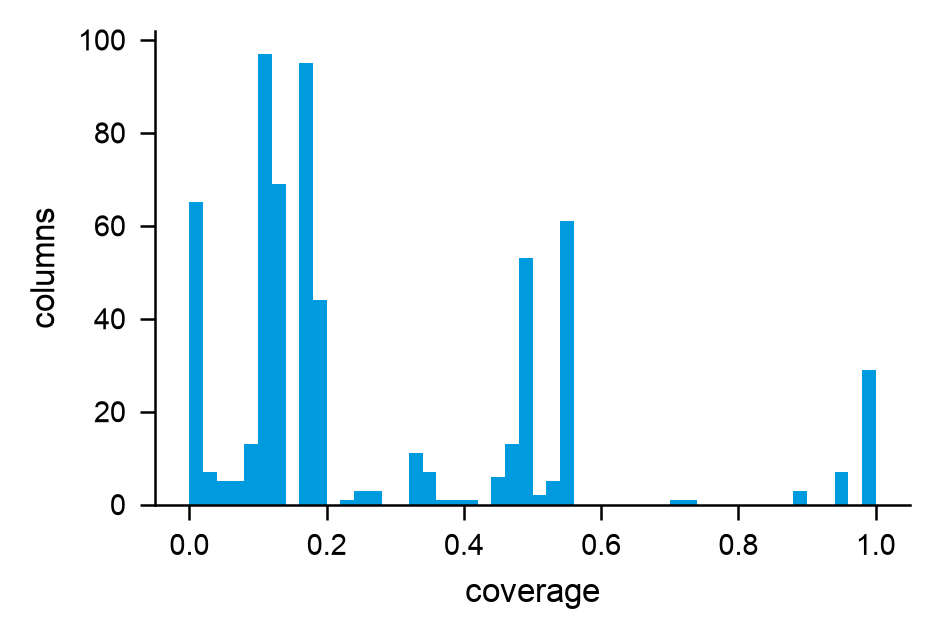

In [23]:
fig, ax = plt.subplots(figsize=(3, 2))
ax.hist(inventory.coverage, bins=50, color="#009ADE")
ax.set_xlabel("coverage")
ax.set_ylabel("columns")
fig.tight_layout(pad=0.3)
plt.show()

In [24]:
inventory[inventory.status.eq("near constant")][
    ["family", "present_modal_share", "coverage", "distinct"]
].sort_values("present_modal_share", ascending=False)

,family,present_modal_share,coverage,distinct
feature,,,,
vep_codon_degeneracy,other,0.975453,0.545539,2
vep_gnomADe_ASJ_AF,frequency,0.955211,0.334330,80
vep_PHENO,clinical,0.946142,0.354269,2
vep_gnomADe_MID_AF,frequency,0.942350,0.334330,93
vep_gnomADe_FIN_AF,frequency,0.919734,0.334330,141
vep_TSL,other,0.913120,0.889482,3
vep_TSL_dbnsfp,other,0.913120,0.889482,3
interface_count,structure,0.907491,0.546536,50
is_in_interface,structure,0.907491,0.546536,2


In [25]:
inventory[inventory.status.eq("gene or transcript level")][
    ["family", "gene_variance", "values_per_gene", "distinct"]
].sort_values("values_per_gene")

,family,gene_variance,values_per_gene,distinct
feature,,,,
in_predicted_pocket,structure,0.282688,1.900000,2
vep_bStatistic,conservation,0.966792,11.833333,287
vep_bStatistic_converted_rankscore,conservation,0.951459,11.833333,287


### Borderline features


In [26]:
borderline = inventory[
    inventory.status.eq("kept")
    & inventory.gene_variance.between(0.5, REGIONAL_LIMIT, inclusive="right")
]
borderline[["family", "gene_variance", "values_per_gene"]]

,family,gene_variance,values_per_gene
feature,,,
vep_GERP++_NR,conservation,0.521685,31.200000
vep_MutFormer_rankscore,pathogenicity,0.674291,158.833333
vep_MutFormer_score,pathogenicity,0.676581,172.566667


In [27]:
print(f"{len(USABLE)} usable numeric features")

117 usable numeric features


## Categorical features


In [28]:
missense = variants[variants.codon_mutation_category.eq("Missense")]
categorical = inventory[inventory.kind.eq("categorical")].copy()
columns = categorical.index
categorical["levels"] = variants[columns].nunique()
categorical["levels_in_missense"] = missense[columns].nunique()
categorical["modal_in_missense"] = missense[columns].apply(
    lambda s: s.value_counts(normalize=True).max()
)

In [29]:
GENE_COUNT = variants.gene.nunique()
ARCHAIC = ("Neandertal", "Denisova", "Ancestral_allele")
ALLELE = ("Allele", "REF_ALLELE", "ref", "alt")


def categorical_verdict(column, row):
    stem = column.replace("vep_", "")
    if row.positional:
        return "identifier"
    if stem.endswith("_pred"):
        return "threshold on its own score"
    if row.levels <= 1:
        return "single valued"
    if row.levels == GENE_COUNT:
        return "gene identity"
    if row.levels_in_missense <= 1 or row.modal_in_missense > 0.95:
        return "constant within missense"
    if stem in ALLELE:
        return "allele or strand encoding"
    if stem.endswith(("_POP", "_POPS")):
        return "population label"
    if "clnsig" in stem.lower():
        return "clinical label"
    if any(word in stem for word in ARCHAIC):
        return "archaic or ancestral allele"
    return "recovered as dummies"


categorical["verdict"] = [categorical_verdict(c, categorical.loc[c])
                          for c in categorical.index]
categorical.verdict.value_counts().rename("columns").to_frame()

,columns
verdict,
identifier,10
threshold on its own score,9
gene identity,5
single valued,5
archaic or ancestral allele,4
recovered as dummies,3
constant within missense,2
population label,2
allele or strand encoding,2


In [30]:
categorical[["levels", "levels_in_missense", "modal_in_missense", "verdict"]].sort_values(
    ["verdict", "levels_in_missense"], ascending=[True, False]
)

,levels,levels_in_missense,modal_in_missense,verdict
feature,,,,
vep_alt,2,2,0.537475,allele or strand encoding
vep_ref,2,2,0.537214,allele or strand encoding
vep_AltaiNeandertal,5,5,0.437014,archaic or ancestral allele
vep_ChagyrskayaNeandertal,4,4,0.437158,archaic or ancestral allele
vep_VindijiaNeandertal,4,4,0.437158,archaic or ancestral allele
vep_Denisova,3,3,0.436581,archaic or ancestral allele
vep_clinvar_clnsig,9,9,0.758319,clinical label
vep_Consequence,15,3,0.969155,constant within missense
vep_IMPACT,4,2,0.997838,constant within missense


### Recovered as dummies


In [31]:
RECOVERED = list(categorical.index[categorical.verdict.eq("recovered as dummies")])
dummies = pd.get_dummies(
    variants[RECOVERED].astype("string"), prefix_sep="=", dummy_na=False, dtype=float
)
occupancy = dummies.loc[missense.index].mean()
DUMMY_FEATURES = list(occupancy[occupancy >= 0.01].index)
variants[DUMMY_FEATURES] = dummies[DUMMY_FEATURES]

# the association frames are built from `table`, so the dummies have to reach it too
dummy_by_guide = variants.set_index("guide")[DUMMY_FEATURES]
for frame in (table, coding):
    frame[DUMMY_FEATURES] = dummy_by_guide.reindex(frame.guide).to_numpy()

In [32]:
pd.DataFrame(
    {
        "share of missense edits": occupancy[DUMMY_FEATURES],
        "source": [name.split("=")[0].replace("vep_", "") for name in DUMMY_FEATURES],
    }
).sort_values("share of missense edits", ascending=False)

,share of missense edits,source
vep_am_class=likely_benign,0.478956,am_class
vep_am_class=likely_pathogenic,0.397377,am_class
vep_aaref=A,0.209715,aaref
vep_aaalt=I,0.181897,aaalt
vep_aaalt=N,0.167916,aaalt
vep_aaref=S,0.125252,aaref
vep_aaref=R,0.119487,aaref
vep_am_class=ambiguous,0.118910,am_class
vep_aaalt=T,0.107236,aaalt
vep_aaalt=V,0.102479,aaalt


In [33]:
print(f"{len(RECOVERED)} categorical columns -> {dummies.shape[1]} levels -> "
      f"{len(DUMMY_FEATURES)} dummies carried into the association analysis")

3 categorical columns -> 36 levels -> 31 dummies carried into the association analysis


## Redundant encodings


In [34]:
def partner_of(column):
    """The score column a rank score derives from, under either naming convention."""
    stem = re.sub(r"_(converted_)?rankscore$", "", column)
    return next(
        (c for c in (f"{stem}_score", stem)
         if c in annotation.columns and c != column),
        None,
    )

In [35]:
rankscore_columns = inventory.index[inventory.index.str.endswith("rankscore")]
pairs = {c: partner_of(c) for c in rankscore_columns}
pairs = {rank: score for rank, score in pairs.items() if score}
agreement = []
for rank, score in pairs.items():
    both = variants[[score, rank]].apply(pd.to_numeric, errors="coerce").dropna()
    if len(both) > 50:
        agreement.append({
            "predictor": score.replace("vep_", ""),
            "spearman": both[score].corr(both[rank], method="spearman"),
            "distinct_scores": both[score].nunique(),
            "scores_mapping_to_many_ranks": int(both.groupby(score)[rank].nunique().gt(1).sum()),
            "n": len(both),
        })
agreement = pd.DataFrame(agreement).sort_values("spearman", key=abs)
agreement

,predictor,spearman,distinct_scores,scores_mapping_to_many_ranks,n
30,Polyphen2_HVAR_score,0.929150,872,493,6792
29,Polyphen2_HDIV_score,0.940300,770,403,6794
33,SIFT4G_score,-0.957879,780,518,6584
34,SIFT_score,-0.971215,706,421,6484
26,MutationTaster_score,0.984380,116,109,6416
0,AlphaMissense_score,0.987706,3309,838,6889
28,PROVEAN_score,-0.990859,919,562,6464
39,VEST4_score,0.991952,967,838,7093
7,ESM1b_score,-0.994371,5791,0,7693
13,LIST-S2_score,0.999091,1356,56,3853


In [36]:
agree = int((agreement.spearman.abs() > 0.999).sum())
print(f"{len(rankscore_columns)} rank score columns, {len(agreement)} paired with their score")
print(f"{agree} rank exactly as their score does, {len(agreement) - agree} do not")

50 rank score columns, 50 paired with their score
41 rank exactly as their score does, 9 do not


## Agreement between independent predictors


In [37]:
def numeric(column):
    return pd.to_numeric(variants.get(column), errors="coerce")

In [38]:
COMPARISONS = [
    ("vep_CADD_phred", "vep_REVEL_score", "CADD vs REVEL"),
    ("vep_AlphaMissense_score", "vep_REVEL_score", "AlphaMissense vs REVEL"),
    ("vep_AlphaMissense_score", "vep_ESM1b_score", "AlphaMissense vs ESM1b"),
    ("vep_SIFT_score", "vep_SIFT4G_score", "SIFT vs SIFT4G"),
    ("vep_Polyphen2_HDIV_score", "vep_Polyphen2_HVAR_score", "PolyPhen2 HDIV vs HVAR"),
    ("vep_GERP++_RS", "vep_phyloP100way_vertebrate", "GERP++ vs phyloP"),
    ("vep_phastCons100way_vertebrate", "vep_phyloP100way_vertebrate", "phastCons vs phyloP"),
    ("vep_CADD_phred", "vep_AlphaMissense_score", "CADD vs AlphaMissense"),
]
present = [c for c in COMPARISONS if c[0] in variants.columns and c[1] in variants.columns]
blocks = {
    label: pd.DataFrame({
        "x": pd.to_numeric(variants[a], errors="coerce"),
        "y": pd.to_numeric(variants[b], errors="coerce"),
        "category": variants.codon_mutation_category,
    }).dropna()
    for a, b, label in present
}
agreement_summary = pd.DataFrame(
    [{"comparison": label, "spearman": b.x.corr(b.y, method="spearman"), "n": len(b)}
     for label, b in blocks.items()]
).set_index("comparison")
agreement_summary

,spearman,n
comparison,,
CADD vs REVEL,0.684229,6602
AlphaMissense vs REVEL,0.736309,6553
AlphaMissense vs ESM1b,-0.682247,6889
SIFT vs SIFT4G,0.847566,6483
PolyPhen2 HDIV vs HVAR,0.971934,6791
GERP++ vs phyloP,0.452913,7661
phastCons vs phyloP,0.616895,7661
CADD vs AlphaMissense,0.719584,6889


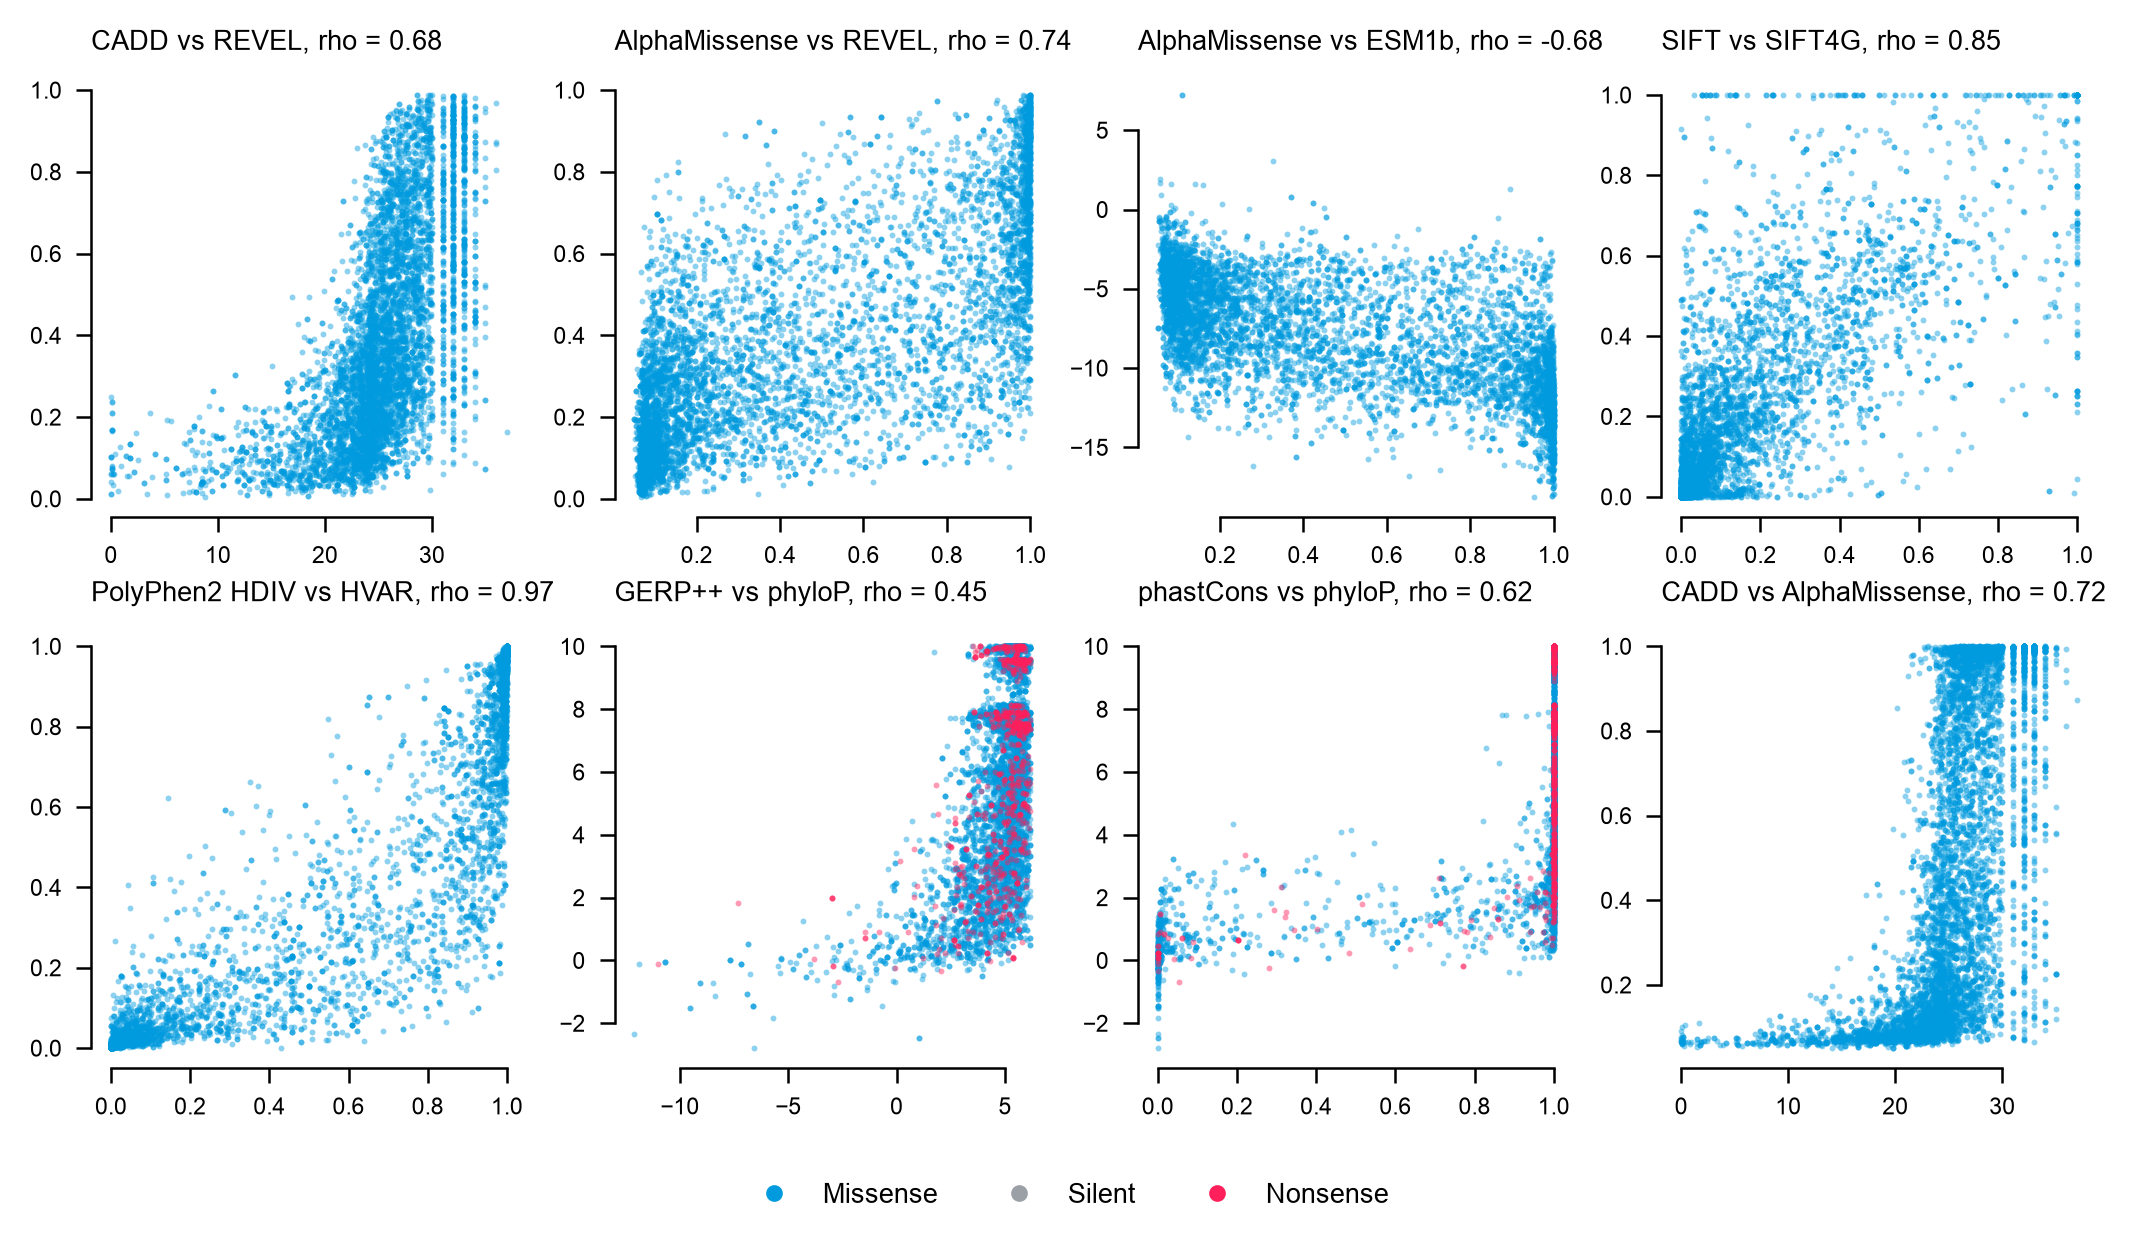

In [39]:
fig, axes = plt.subplots(2, 4, figsize=(7, 4))
for ax, (label, block) in zip(axes.ravel(), blocks.items()):
    for category, part in block.groupby("category"):
        ax.scatter(part.x, part.y, s=2, linewidths=0, alpha=0.45,
                   color=CATEGORY_COLOUR[category], rasterized=True)
    ax.set_title(f"{label}, rho = {agreement_summary.spearman[label]:.2f}",
                 fontsize=6.5, loc="left")
    ax.tick_params(labelsize=5.5)
for ax in axes.ravel()[len(blocks):]:
    ax.set_visible(False)
handles = [plt.Line2D([], [], marker="o", ls="", ms=3, color=colour, label=category)
           for category, colour in CATEGORY_COLOUR.items()]
fig.legend(handles=handles, frameon=False, fontsize=6.5, ncol=3, loc="lower center")
fig.tight_layout(pad=0.4, rect=(0, 0.07, 1, 1))
save_plot(fig, "eda_predictor_agreement")
plt.show()

## Collinearity


In [40]:
THRESHOLD = 0.8          # every pair inside a group correlates at least this much
REFERENCE = "vep_CADD_phred"   # a broadly measured feature to orient the others against

In [41]:
matrix = variants[USABLE].apply(pd.to_numeric, errors="coerce")
matrix = matrix.loc[:, matrix.nunique() > 1]

In [42]:
matrix

,vep_gnomADe_AF,vep_gnomADe_AFR_AF,vep_gnomADe_AMR_AF,vep_gnomADe_EAS_AF,vep_gnomADe_NFE_AF,vep_gnomADe_REMAINING_AF,vep_gnomADe_SAS_AF,vep_MAX_AF,vep_am_pathogenicity,vep_AlphaMissense_rankscore,...,vep_phyloP470way_mammalian_rankscore,vep_popEVE_converted_rankscore,vep_popEVE_score,spliceai_ds_ag,spliceai_ds_al,spliceai_ds_dg,spliceai_ds_dl,foldx_ddg,plddt,blosum62
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.00,0.0,0.0,0.0,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4521,0.66817,...,0.94528,0.73444,-3.672,0.01,0.0,0.0,0.0,NaN,NaN,-2.0
19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0870,0.45055,...,0.94505,0.10216,-2.859,0.00,0.0,0.0,0.0,NaN,NaN,-2.0
20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0870,0.45055,...,0.94505,0.10216,-2.859,0.00,0.0,0.0,0.0,NaN,NaN,-2.0
21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0870,0.45055,...,0.94505,0.10216,-2.859,0.00,0.0,0.0,0.0,NaN,NaN,-2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49999,0.000002,0.0,0.000000,0.0,0.000002,0.000000,0.0,0.000002,0.4302,0.62242,...,NaN,0.92595,-4.263,0.00,0.0,0.0,0.0,NaN,NaN,0.0
50001,0.000002,0.0,0.000000,0.0,0.000002,0.000000,0.0,0.000002,0.4302,0.62242,...,NaN,0.92595,-4.263,0.00,0.0,0.0,0.0,NaN,NaN,0.0
50007,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.98899,-5.236,0.00,0.0,0.0,0.0,NaN,NaN,1.0
50010,0.000004,0.0,0.000199,0.0,0.000000,0.000055,0.0,0.000199,NaN,NaN,...,NaN,NaN,NaN,0.00,0.0,0.0,0.0,NaN,NaN,NaN


### Orientation


In [43]:
orientation = np.sign(
    matrix.corrwith(matrix[REFERENCE], method="spearman")
).replace(0, 1)
oriented = matrix.mul(orientation)
print(f"{int((orientation < 0).sum())} of {len(orientation)} features sign-flipped")

16 of 117 features sign-flipped


In [44]:
spearman = oriented.corr(method="spearman").fillna(0.0)
pearson = oriented.corr(method="pearson").fillna(0.0)
correlation = spearman

### Spearman against Pearson


In [45]:
def trimmed_pearson(first, second, quantile=0.99):
    """Pearson after dropping the most extreme 1% by absolute value."""
    both = oriented[[first, second]].dropna()
    kept = both[both.abs().max(axis=1).le(both.abs().max(axis=1).quantile(quantile))]
    return kept[first].corr(kept[second])


upper = np.triu(np.ones(correlation.shape, dtype=bool), k=1)
rows, columns = np.where(upper & (pearson > THRESHOLD) & (spearman <= THRESHOLD))
disagreeing = list(zip(correlation.index[rows], correlation.index[columns]))

In [46]:
pd.DataFrame(
    [
        {
            "pair": f"{a.replace('vep_', '')} / {b.replace('vep_', '')}",
            "spearman": spearman.loc[a, b],
            "pearson": pearson.loc[a, b],
            "pearson trimmed": trimmed_pearson(a, b),
        }
        for a, b in disagreeing
    ]
).set_index("pair").sort_values("pearson trimmed", ascending=False)

,spearman,pearson,pearson trimmed
pair,,,
CADD_raw / MutationTaster_trees_deleterious,0.706704,0.854828,0.854828
gnomADe_AF / gnomADe_REMAINING_AF,0.614393,0.999725,0.853689
CADD_raw_rankscore / Eigen-PC-raw_coding,0.764792,0.827416,0.814005
CADD_raw_rankscore / Eigen-PC-raw_coding_rankscore,0.764793,0.815270,0.812283
MetaRNN_rankscore / PHACTboost_rankscore,0.799421,0.806789,0.806023
ClinPred_rankscore / Eigen-raw_coding_rankscore,0.795935,0.808785,0.804267
ClinPred_rankscore / Eigen-raw_coding,0.795936,0.805968,0.801926
MetaRNN_rankscore / MutScore_rankscore,0.794337,0.802768,0.799829
gnomADe_REMAINING_AF / MAX_AF,0.556966,0.951760,0.627533


In [47]:
survives = sum(1 for a, b in disagreeing if trimmed_pearson(a, b) > THRESHOLD)
print(f"{len(disagreeing) - survives} of {len(disagreeing)} pairs lose their Pearson when "
      f"trimmed; {survives} keep it")

26 of 33 pairs lose their Pearson when trimmed; 7 keep it


## Correlated groups


In [48]:
tree = linkage(squareform(1 - correlation.to_numpy(), checks=False), method="complete")
groups = pd.Series(fcluster(tree, t=1 - THRESHOLD, criterion="distance"), index=correlation.index)

In [49]:
def group_summary(members):
    inside = correlation.loc[members, members]
    off_diagonal = inside.where(~np.eye(len(members), dtype=bool))
    return pd.Series({
        "size": len(members),
        "family": inventory.family[members].mode().iat[0],
        "weakest pair": off_diagonal.min().min(),
        "members": ", ".join(inside.index.str.replace("vep_", "", regex=False)),
    })


correlated = (
    pd.DataFrame([group_summary(list(g.index)) for _, g in groups.groupby(groups)])
    .sort_values("size", ascending=False)
    .reset_index(drop=True)
)
correlated.index += 1
correlated[correlated["size"] > 1]

,size,family,weakest pair,members
1,13,pathogenicity,0.803347,"am_pathogenicity, AlphaMissense_rankscore, Alp..."
2,6,pathogenicity,0.864434,"BayesDel_addAF_rankscore, BayesDel_addAF_score..."
3,6,pathogenicity,0.984469,"Eigen-PC-phred_coding, Eigen-PC-raw_coding, Ei..."
4,4,pathogenicity,0.975792,"MetaLR_rankscore, MetaLR_score, MetaSVM_ranksc..."
5,4,pathogenicity,0.800063,"MutScore_rankscore, MutScore_score, PHACTboost..."
6,4,pathogenicity,0.982788,"MutationTaster_rankscore, MutationTaster_score..."
7,4,pathogenicity,0.906440,"MisFit_D_rankscore, MisFit_D_score, MisFit_S_r..."
8,4,pathogenicity,0.905192,"Polyphen2_HDIV_rankscore, Polyphen2_HDIV_score..."
9,4,pathogenicity,0.865990,"MetaRNN_rankscore, MetaRNN_score, VEST4_ranksc..."
10,4,pathogenicity,0.810482,"SIFT4G_converted_rankscore, SIFT4G_score, SIFT..."


In [50]:
eigenvalues = np.linalg.eigvalsh(correlation.to_numpy())
eigenvalues = eigenvalues[eigenvalues > 0]
effective = eigenvalues.sum() ** 2 / (eigenvalues**2).sum()
print(f"{len(correlation)} features span {effective:.1f} effective dimensions")

117 features span 3.7 effective dimensions


In [51]:
print(f"{len(correlation)} features form {groups.nunique()} groups, of which "
      f"{int((correlated['size'] > 1).sum())} hold more than one feature")
print(f"weakest within-group correlation anywhere: {correlated['weakest pair'].min():.4f}")

117 features form 49 groups, of which 34 hold more than one feature
weakest within-group correlation anywhere: 0.8001


In [52]:
REDUNDANT_LIMIT = 0.9
redundant = pd.Series(
    fcluster(tree, t=1 - REDUNDANT_LIMIT, criterion="distance"), index=correlation.index
)
keep = (
    inventory.loc[correlation.index, ["coverage"]]
    .assign(
        group=redundant,
        derived=correlation.index.str.contains("rankscore|converted", case=False),
        name_length=correlation.index.str.len(),
    )
    .sort_values(["derived", "coverage", "name_length"], ascending=[True, False, True])
    .groupby("group")
    .head(1)
    .index
)
DROPPED = correlation.index.difference(keep)
USABLE = [c for c in USABLE if c not in set(DROPPED)]
inventory.loc[DROPPED, "status"] = f"redundant above {REDUNDANT_LIMIT}"
print(f"{len(DROPPED)} of {len(correlation)} features dropped, {len(USABLE)} kept")

61 of 117 features dropped, 56 kept


In [53]:
members = pd.DataFrame(
    {"group": redundant.to_numpy(), "kept": correlation.index.isin(keep)},
    index=correlation.index.str.replace("vep_", "", regex=False),
)
members = members[members.group.map(members.group.value_counts()) > 1]
members.sort_values(["group", "kept"], ascending=[True, False])

,group,kept
GERP_92_mammals,6,True
GERP_92_mammals_rankscore,6,False
phastCons100way_vertebrate,7,True
phastCons100way_vertebrate_rankscore,7,False
phyloP100way_vertebrate,8,True
...,...,...
phyloP17way_primate_rankscore,43,False
phastCons17way_primate,44,True
phastCons17way_primate_rankscore,44,False
GERP++_RS,45,True


## Feature representation


In [54]:
structural = (
    unique_variants.groupby("category")[USABLE].apply(lambda b: b.notna().mean())
    .T[["Missense", "Silent", "Nonsense"]]
)
missense_only = structural[(structural.Missense > 0.8) & (structural.Silent < 0.01)]
everywhere = structural[structural.min(axis=1) > 0.8]
print(f"{len(missense_only)} of {len(USABLE)} features are measured for missense edits "
      f"and absent for silent ones")
print(f"  of those, {int(missense_only.Nonsense.lt(0.01).sum())} are absent for nonsense too")
print(f"{len(everywhere)} measured across all three categories: "
      f"{', '.join(everywhere.index.str.replace('vep_', '', regex=False))}")

41 of 56 features are measured for missense edits and absent for silent ones
  of those, 23 are absent for nonsense too
4 measured across all three categories: spliceai_ds_ag, spliceai_ds_al, spliceai_ds_dg, spliceai_ds_dl


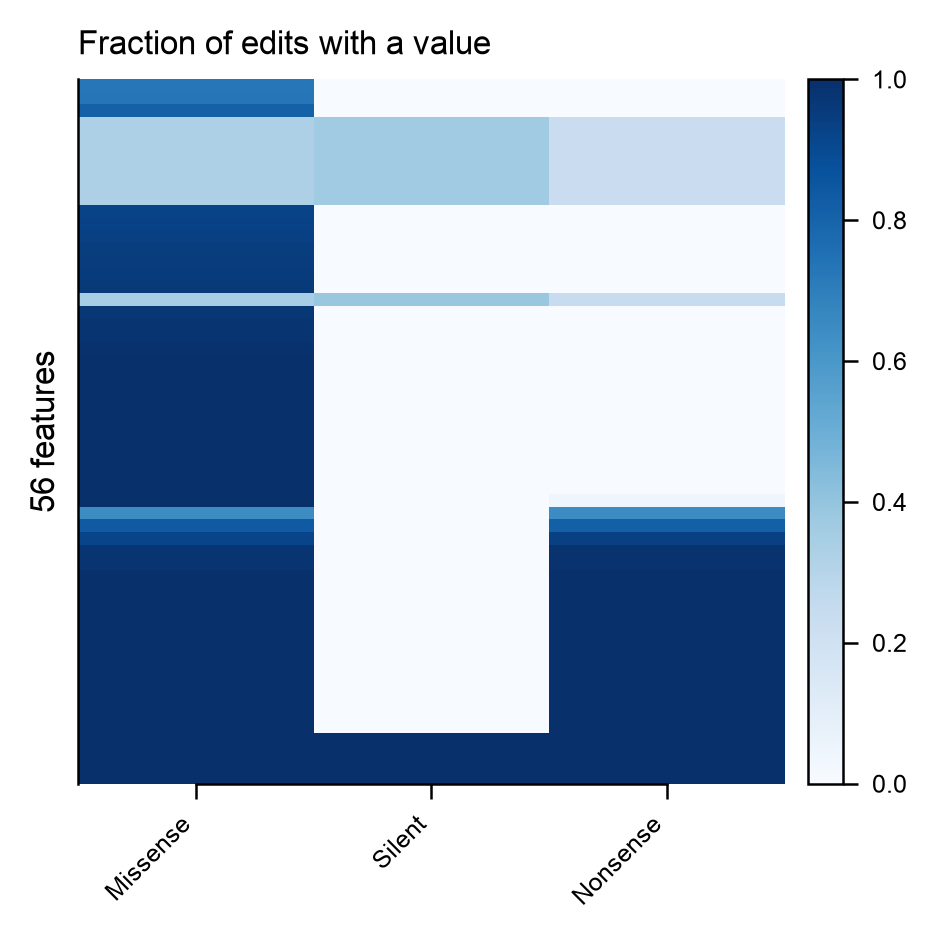

In [55]:
fig, ax = plt.subplots(figsize=(3, 3))
order = structural.mean(axis=1).sort_values().index
image = ax.imshow(structural.loc[order], cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(structural.shape[1]))
ax.set_xticklabels(structural.columns, rotation=45, ha="right", fontsize=6)
ax.set_yticks([])
ax.set_ylabel(f"{len(order)} features")
ax.set_title("Fraction of edits with a value", fontsize=8, loc="left")
fig.colorbar(image, ax=ax, fraction=0.05, pad=0.03).ax.tick_params(labelsize=6)
fig.tight_layout(pad=0.3)
save_plot(fig, "eda_structural_missingness")
plt.show()

In [56]:
numeric_usable = variants[USABLE].apply(pd.to_numeric, errors="coerce")
shape = pd.DataFrame({
    "skewness": numeric_usable.skew(),
    "zero_share": numeric_usable.eq(0).sum() / numeric_usable.notna().sum(),
    "max": numeric_usable.max(),
    "family": inventory.family.reindex(USABLE),
})
heavy = shape[shape.skewness.abs() > 3].sort_values("skewness", key=abs, ascending=False)
print(f"{len(heavy)} of {len(shape)} features are strongly skewed (|skew| > 3)")
heavy[["family", "skewness", "zero_share", "max"]].head(8)

17 of 56 features are strongly skewed (|skew| > 3)


,family,skewness,zero_share,max
vep_gnomADe_EAS_AF,frequency,31.969001,0.825346,0.8995
vep_gnomADe_SAS_AF,frequency,28.092176,0.705005,0.8236
vep_gnomADe_NFE_AF,frequency,27.848651,0.263685,0.7314
vep_gnomADe_AMR_AF,frequency,27.747823,0.790628,0.8520
vep_gnomADe_AF,frequency,27.680331,0.058573,0.7359
vep_gnomADe_REMAINING_AF,frequency,27.398747,0.709904,0.7295
vep_MAX_AF,frequency,23.110213,0.050851,0.9187
vep_gnomADe_AFR_AF,frequency,21.866981,0.794036,0.6864


In [57]:
shape.groupby("family").skewness.agg(["mean", "max"])

,mean,max
family,,
conservation,-2.311434,-0.485731
frequency,26.964240,31.969001
other,0.319231,0.319231
pathogenicity,-0.183832,1.948819
splice,7.604047,8.694198
structure,1.463618,4.852836


In [58]:
calls = []
for column in inventory.index[inventory.kind.eq("categorical")]:
    partner = re.sub(r"_pred$", "", column) + "_score"
    if partner not in variants.columns:
        continue
    block = pd.DataFrame({
        "call": variants[column],
        "score": pd.to_numeric(variants[partner], errors="coerce"),
    }).dropna()
    if len(block) < 100 or block.call.nunique() < 2 or not block.score.std():
        continue
    by_call = block.groupby("call").score.agg(["std", "size"]).query("size > 5")
    # the reference point is a pure threshold on the score at the same class balance
    cut = block.score.quantile(1 - (block.call == block.call.mode().iat[0]).mean())
    halves = block.groupby(block.score > cut).score.agg(["std", "size"]).query("size > 5")
    if len(by_call) < 2:
        continue
    calls.append({
        "feature": column.replace("vep_", ""),
        "classes": block.call.nunique(),
        "within/total": by_call["std"].mean() / block.score.std(),
        "a threshold gives": halves["std"].mean() / block.score.std(),
        "n": len(block),
    })
pd.DataFrame(calls).set_index("feature")

,classes,within/total,a threshold gives,n
feature,,,,
BayesDel_addAF_pred,2,0.553631,0.553631,7693
BayesDel_noAF_pred,2,0.543511,0.543556,7693
ClinPred_pred,2,0.477657,0.477657,6968
GPN_MSA_pred,2,0.599302,0.541757,7693
M-CAP_pred,2,0.536280,0.536280,6922
MetaLR_pred,2,0.525994,0.529468,6938
MetaSVM_pred,2,0.503783,0.507542,6938
PrimateAI_pred,2,0.539208,0.540468,6869
fathmm-XF_coding_pred,2,0.416424,0.416424,7520


### Missingness map


In [59]:
missing = variants[USABLE].isna()
print(f"{len(USABLE)} features reduce to {len(missing.T.drop_duplicates())} distinct "
      f"missingness patterns")
print(f"{int((~missing.any(axis=1)).sum()):,} of {len(variants):,} variants have every "
      f"feature measured")

56 features reduce to 32 distinct missingness patterns
661 of 14,043 variants have every feature measured


In [60]:
category_order = [c for c in ["Missense", "Nonsense", "Silent"]
                  if c in set(variants.codon_mutation_category)]
column_order = np.concatenate(
    [np.flatnonzero(variants.codon_mutation_category.eq(c)) for c in category_order]
)
widths = variants.codon_mutation_category.value_counts()[category_order]
picture = missing[missing.mean().sort_values().index].to_numpy()[column_order].T

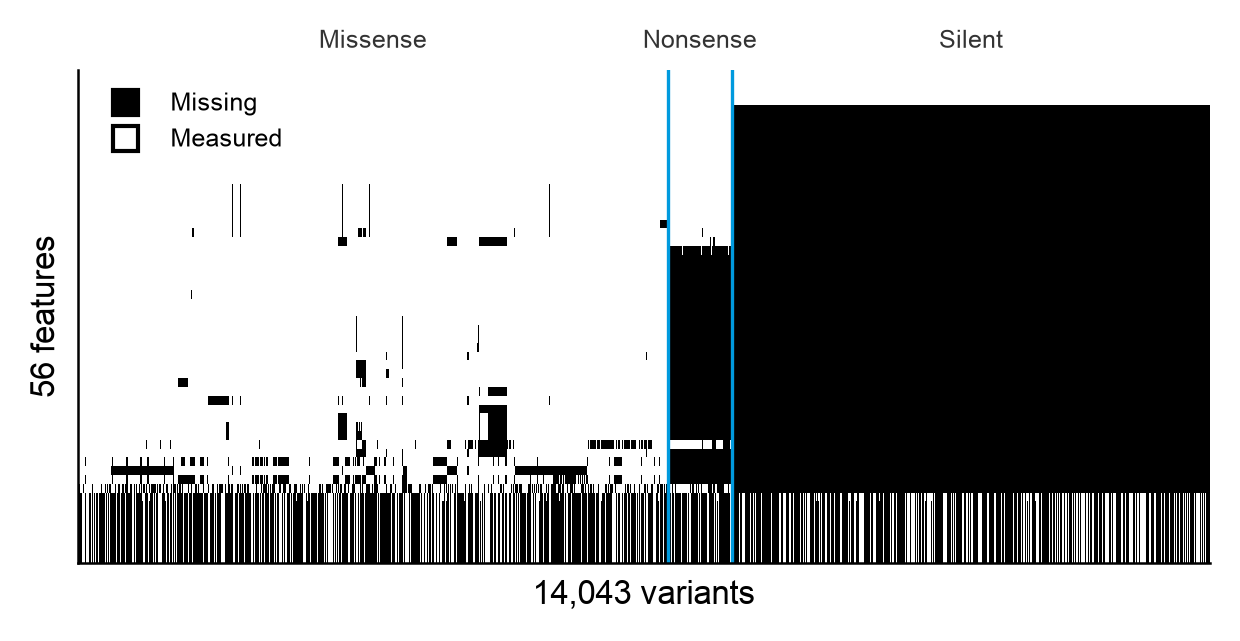

In [71]:
fig, ax = plt.subplots(figsize=(4, 2))
ax.imshow(picture, cmap="Greys", vmin=0, vmax=1, aspect="auto", interpolation="nearest")
for edge in widths.cumsum()[:-1]:
    ax.axvline(edge, color="#009ADE", lw=0.8)
for centre, category in zip(widths.cumsum() - widths / 2, category_order):
    ax.text(centre, -3, category, ha="center", fontsize=6, color="#333333")
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(f"{len(variants):,} variants")
ax.set_ylabel(f"{len(USABLE)} features")
ax.legend(
    handles=[
        plt.Line2D([], [], marker="s", ls="", color="black", label="Missing"),
        plt.Line2D([], [], marker="s", ls="", markerfacecolor="white",
                   markeredgecolor="black", label="Measured"),
    ],
    loc="upper left", fontsize=6, frameon=False,
)
fig.tight_layout(pad=0.3)
save_plot(fig, "eda_missingness_map")
plt.show()

## Correlation map


In [62]:
HIGHLIGHT = 0.65
MAX_LABELS = 50
LABEL_FONT = 5.0

# every filter has been applied by this point, so the map is read on the surviving set
kept = [c for c in correlation.index if c in set(USABLE)]
kept_correlation = correlation.loc[kept, kept]
kept_tree = linkage(
    squareform(1 - kept_correlation.to_numpy(), checks=False), method="complete"
)
order = kept_correlation.index[leaves_list(kept_tree)]
ordered = kept_correlation.loc[order, order]
highlight_groups = pd.Series(
    fcluster(kept_tree, t=1 - HIGHLIGHT, criterion="distance"),
    index=kept_correlation.index,
).reindex(order).to_numpy()

starts = np.r_[0, np.flatnonzero(np.diff(highlight_groups)) + 1]
sizes = np.diff(np.r_[starts, len(order)])
runs = pd.DataFrame({"begin": starts, "size": sizes}).query("size > 1")
runs["strength"] = [
    ordered.iloc[b:b + s, b:b + s].where(~np.eye(s, dtype=bool)).stack().mean()
    for b, s in zip(runs.begin, runs["size"])
]

# the most tightly correlated groups are marked first, until the label budget is spent
blocks, budget = [], MAX_LABELS
for _, group in runs.sort_values("strength", ascending=False).iterrows():
    if group["size"] <= budget:
        blocks.append((int(group.begin), int(group["size"])))
        budget -= int(group["size"])
blocks.sort()
labelled = [(b + i, order[b + i].replace("vep_", "")) for b, s in blocks for i in range(s)]

families = sorted(inventory.family[order].dropna().unique())
palette = dict(zip(families, plt.cm.tab10.colors))
family_index = inventory.family[order].map({f: i for i, f in enumerate(families)})
print(f"{len(order)} surviving features, {len(blocks)} groups boxed, "
      f"{len(labelled)} labelled")

56 surviving features, 10 groups boxed, 31 labelled


### Drawing the map


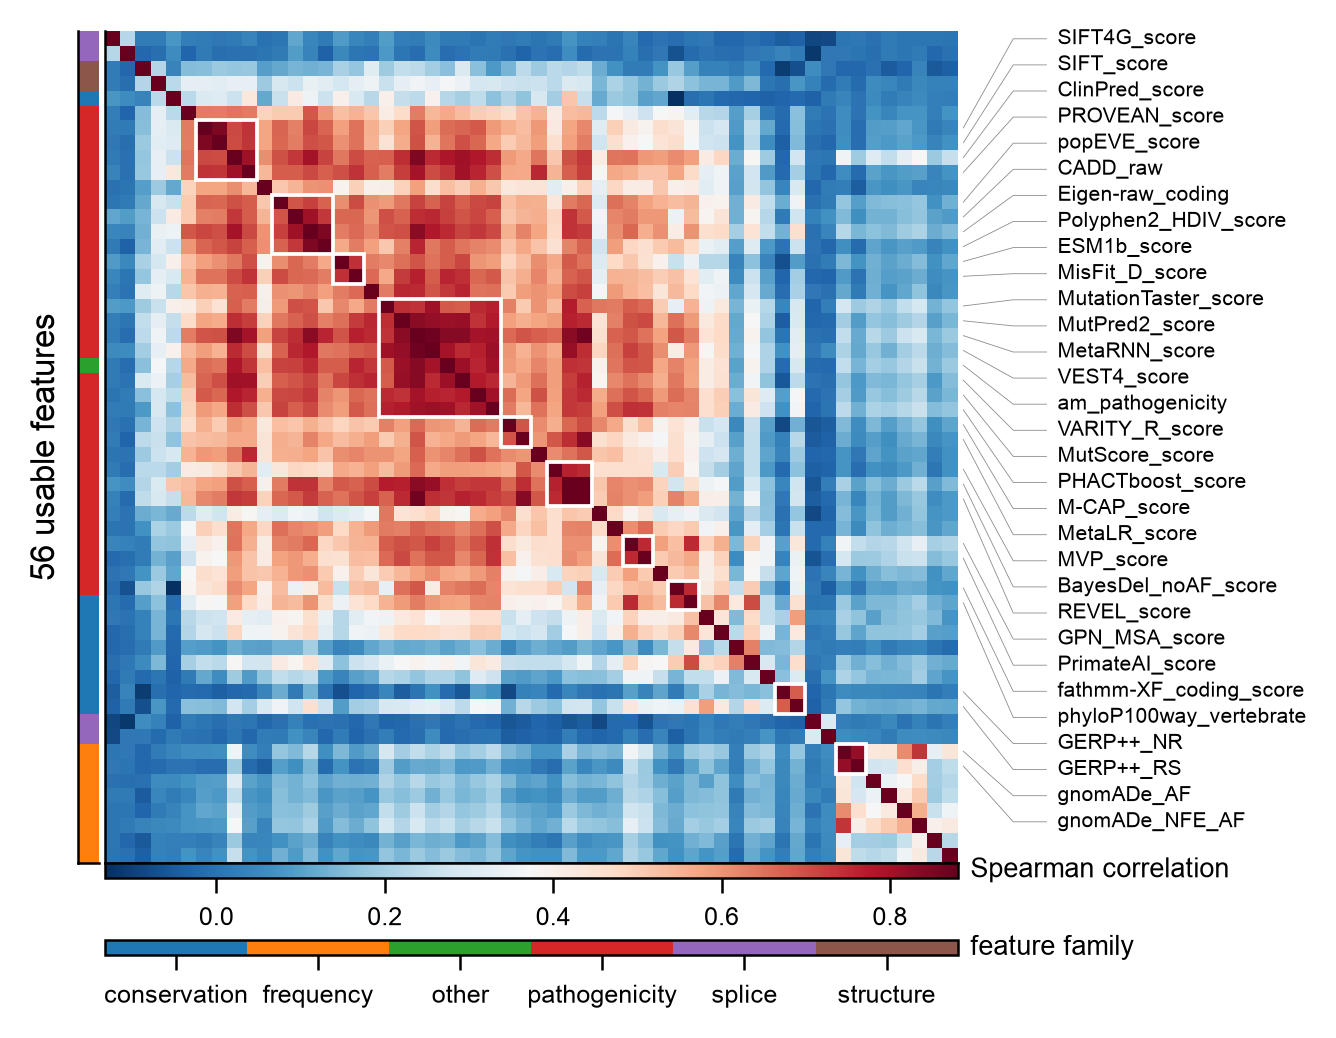

In [65]:
def spread(values, gap, low, high):
    """Push labels apart to `gap`, keeping their order and staying inside the panel.

    If they cannot all fit at that gap it shrinks to what the panel allows, which beats
    clipping: clipping silently stacks labels against the edges.
    """
    out = np.asarray(values, dtype=float).copy()
    if len(out) > 1:
        gap = min(gap, (high - low) / (len(out) - 1))
    out[0] = max(out[0], low)
    for i in range(1, len(out)):
        out[i] = max(out[i], out[i - 1] + gap)
    if out[-1] > high:
        out -= out[-1] - high
    for i in range(len(out) - 2, -1, -1):
        out[i] = min(out[i], out[i + 1] - gap)
    return out


fig = plt.figure(figsize=(5, 4))
grid = fig.add_gridspec(
    4, 3, width_ratios=[1, 40, 13], height_ratios=[60, 1.1, 4.5, 1.1],
    hspace=0.0, wspace=0.015,
)
ax_strip, ax_map = fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1])
ax_labels = fig.add_subplot(grid[0, 2], sharey=ax_map)
cax_correlation, cax_family = fig.add_subplot(grid[1, 1]), fig.add_subplot(grid[3, 1])
fig.add_subplot(grid[2, 1]).axis("off")      # spacer, keeps the two scales apart

strip = ax_strip.imshow(
    family_index.to_numpy().reshape(-1, 1), aspect="auto",
    cmap=mcolors.ListedColormap([palette[f] for f in families]),
    vmin=-0.5, vmax=len(families) - 0.5,
)
ax_strip.set(xticks=[], yticks=[], ylabel=f"{len(order)} usable features")

# the colour scale spans the values actually present, not a nominal -1 to 1
off_diagonal = ordered.where(~np.eye(len(order), dtype=bool)).stack()
image = ax_map.imshow(ordered, cmap="RdBu_r", aspect="auto",
                      vmin=off_diagonal.min(), vmax=off_diagonal.max())
for begin, size in blocks:
    ax_map.add_patch(plt.Rectangle((begin - 0.5, begin - 0.5), size, size,
                                   fill=False, edgecolor="white", lw=0.9))
ax_map.set(xticks=[], yticks=[])

# one line of text occupies this many matrix rows, so labels cannot sit closer
panel_height = ax_map.get_position().height * fig.get_figheight()
gap = len(order) * (LABEL_FONT * 1.6 / 72) / panel_height
rows = [position for position, _ in labelled]
targets = spread(rows, gap, 0, len(order) - 1 - gap)

ax_labels.set(xlim=(0, 1), ylim=ax_map.get_ylim())
ax_labels.axis("off")
for row, target, (_, name) in zip(rows, targets, labelled):
    ax_labels.plot([0.0, 0.18, 0.30], [row, target, target], color="0.55", lw=0.2,
                   clip_on=False, solid_joinstyle="round")
    ax_labels.text(0.34, target, name, fontsize=LABEL_FONT, va="center", ha="left")

for bar, cax, label, ticks in [
    (image, cax_correlation, "Spearman correlation", None),
    (strip, cax_family, "feature family", range(len(families))),
]:
    colourbar = fig.colorbar(bar, cax=cax, orientation="horizontal", ticks=ticks)
    colourbar.ax.tick_params(labelsize=6)
    cax.text(1.015, 0.5, label, transform=cax.transAxes, ha="left", va="center",
             fontsize=6.5)
cax_family.set_xticklabels(families, fontsize=6)

save_plot(fig, "eda_correlation_map")
plt.show()

## Distributions by consequence


In [66]:
shown = (
    correlated[correlated["size"] > 1].head(6).members.str.split(", ").str[0]
    .radd("vep_")
    .pipe(lambda s: s.where(s.isin(variants.columns), s.str.replace("vep_", "", regex=False)))
    .pipe(lambda s: s[s.isin(variants.columns)])
    .tolist()
)
shown

['vep_am_pathogenicity',
 'vep_BayesDel_addAF_rankscore',
 'vep_Eigen-PC-phred_coding',
 'vep_MetaLR_rankscore',
 'vep_MutScore_rankscore',
 'vep_MutationTaster_rankscore']

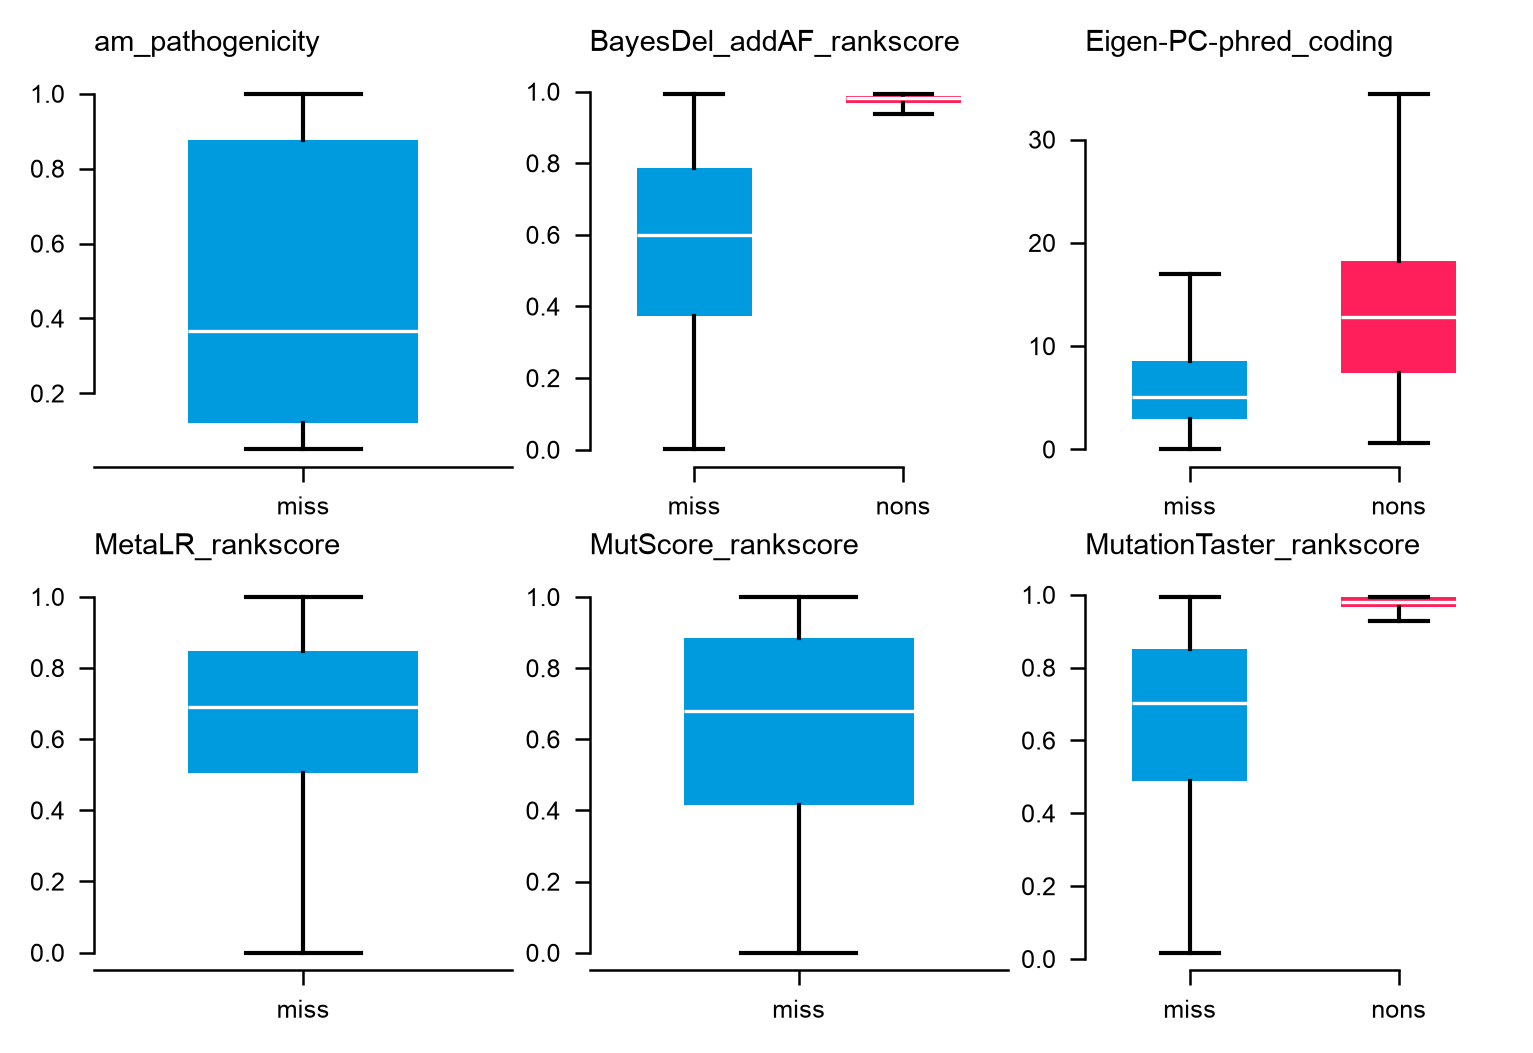

In [67]:
fig, axes = plt.subplots(2, 3, figsize=(5.0, 3.4))
for ax, feature in zip(axes.ravel(), shown):
    data = {
        category: pd.to_numeric(part[feature], errors="coerce").dropna()
        for category, part in variants.groupby("codon_mutation_category")
        if category in CATEGORY_COLOUR and part[feature].notna().sum() >= 20
    }
    parts = ax.boxplot(data.values(), widths=0.55, patch_artist=True, showfliers=False,
                       medianprops=dict(color="white", lw=0.8))
    for patch, category in zip(parts["boxes"], data):
        patch.set_facecolor(CATEGORY_COLOUR[category])
        patch.set_linewidth(0)
    ax.set_xticklabels([c[:4].lower() for c in data], fontsize=6)
    ax.set_title(feature.replace("vep_", ""), fontsize=7, loc="left")
    ax.tick_params(labelsize=6)
for ax in axes.ravel()[len(shown):]:
    ax.set_visible(False)
fig.tight_layout(pad=0.4)
save_plot(fig, "eda_distributions_by_consequence")
plt.show()

## Summary


In [68]:
report = inventory[
    ["family", "kind", "coverage", "distinct", "positional", "modal_share",
     "present_modal_share", "gene_variance", "values_per_gene", "status"]
].copy()
report["correlation_group"] = groups.reindex(report.index)
report["group_size"] = report.correlation_group.map(groups.value_counts())
report = (
    report.set_axis(report.index.str.replace("vep_", "", regex=False))
    .sort_values(["status", "family", "coverage"], ascending=[True, True, False])
)
report.to_csv(C.DATA / "features_annotation_inventory.csv")

selected = report[report.status.eq("kept")][["family", "kind", "coverage"]]
selected.to_csv(C.DATA / "features_selected.csv")
print(f"{len(selected)} features exported for notebook 04")

56 features exported for notebook 04


In [69]:
report

,family,kind,coverage,distinct,positional,modal_share,present_modal_share,gene_variance,values_per_gene,status,correlation_group,group_size
feature,,,,,,,,,,,,
CLIN_SIG,clinical,text,0.222744,97,False,NaN,NaN,NaN,NaN,coverage below 30%,NaN,NaN
clinvar_id,clinical,continuous,0.133091,1416,False,NaN,NaN,NaN,NaN,coverage below 30%,NaN,NaN
clinvar_clnsig,clinical,categorical,0.132094,9,False,NaN,NaN,NaN,NaN,coverage below 30%,NaN,NaN
clinvar_trait,clinical,text,0.132094,347,False,NaN,NaN,NaN,NaN,coverage below 30%,NaN,NaN
clinvar_MedGen_id,clinical,text,0.131169,324,False,NaN,NaN,NaN,NaN,coverage below 30%,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
GENE_PHENO,clinical,binary,0.890550,1,False,NaN,NaN,NaN,NaN,single valued,NaN,NaN
VARIANT_CLASS,other,categorical,1.000000,1,False,NaN,NaN,NaN,NaN,single valued,NaN,NaN
SYMBOL_SOURCE,other,categorical,1.000000,1,False,NaN,NaN,NaN,NaN,single valued,NaN,NaN


In [70]:
report["status"].value_counts()

status
coverage below 30%          354
redundant above 0.9          61
kept                         56
positional or identifier     49
no values                    37
not numeric                  32
near constant                12
single valued                 5
gene or transcript level      3
Name: count, dtype: int64